# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [ ]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [ ]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset_Download.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [ ]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

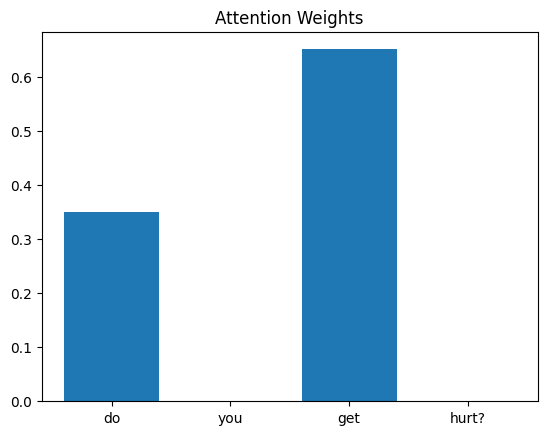

In [ ]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

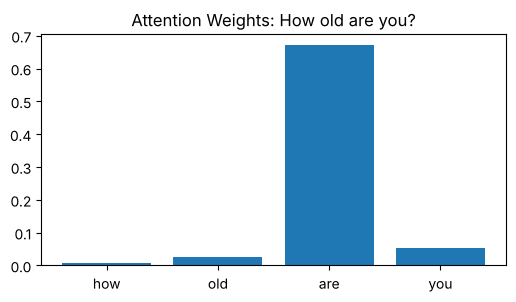

Question: How old are you?
Predicted answer: People created me.
Highest attention word: are (0.670)



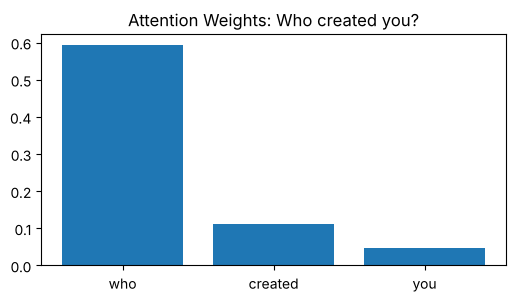

Question: Who created you?
Predicted answer: People created me.
Highest attention word: who (0.592)



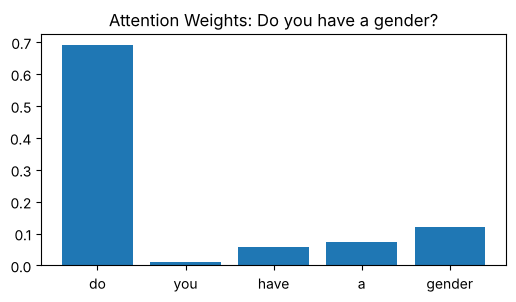

Question: Do you have a gender?
Predicted answer: I don't have a body.
Highest attention word: do (0.690)



In [7]:
def plot_attention(question_text):
    index = df.index[df["question"] == question_text.lower()][0]
    words = [tokenizer.index_word[i] for i in X[index].tolist() if i != 0]
    with torch.no_grad():
        prediction, weights = model(X[index:index + 1])
    word_weights = weights[0, :len(words)].tolist()
    top_word = words[word_weights.index(max(word_weights))]
    plt.figure(figsize=(6, 3))
    plt.bar(words, word_weights)
    plt.title(f"Attention Weights: {question_text}")
    plt.show()
    print(f"Question: {question_text}")
    print(f"Predicted answer: {df[df['answer_id'] == prediction.argmax(1).item()]['answer'].iloc[0]}")
    print(f"Highest attention word: {top_word} ({max(word_weights):.3f})")
    print()
    return top_word

questions = ["How old are you?", "Who created you?", "Do you have a gender?"]

for q in questions:
    plot_attention(q)

The words with the highest attention weights were **"are"** in "How old are you?", **"who"** in "Who created you?" and **"do"** in "Do you have a gender?". Only "who" is really important for understanding its question, because it shows the question is about who made the model. The words that carry the real meaning, such as **"old"** and **"gender"**, did not get the highest weights. This shows that the model often focuses on common words that start or structure the question, which also explains why some of its predicted answers are wrong. The model is small and trained for only a few epochs on a small dataset, so its attention does not always match what a human would consider important.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

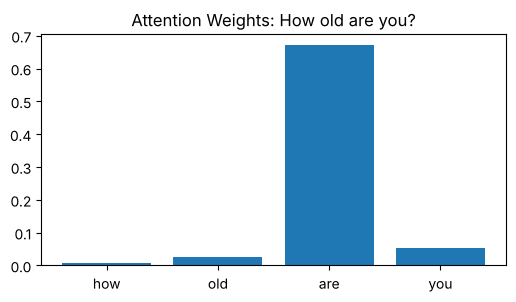

Question: How old are you?
Predicted answer: People created me.
Highest attention word: are (0.670)



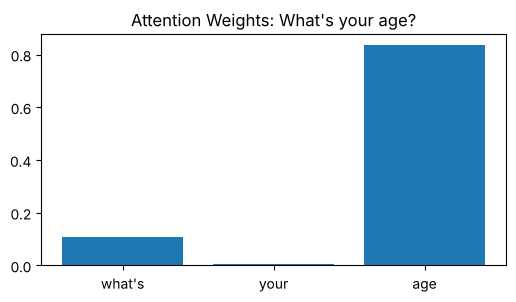

Question: What's your age?
Predicted answer: Not at all.
Highest attention word: age (0.834)



In [8]:
similar_questions = ["How old are you?", "What's your age?"]

for q in similar_questions:
    plot_attention(q)

The two questions "How old are you?" and "What's your age?" have the same meaning, but the model focused on different words: **"are"** in the first question and **"age"** in the second. In the second question the model focused on the most meaningful word, while in the first it focused on a common word instead of "old". The two questions were also given different answers, even though they should have the same one. This suggests that attention depends on the exact words and their positions in each sentence, not on the meaning itself, and that the model needs more training data and training to learn that different words like "old" and "age" mean the same thing.